# Case Study 2 - Mall Customer Segementation

Dataset is `customers.csv` from folder `mall` and it has cleaned data about customers.

## Loading Data and Basic Information

In [1]:
import pandas as pd
import os.path as osp
import seaborn as sns

# load the dataset
path = osp.join('..', '..', 'data', 'mall')
df = pd.read_csv(osp.join(path,'customers.csv'))
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [2]:
df['CustomerID'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [3]:
df['Gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Observations:
- Total Rows: 
    - 200
- Total Columns: 
    - 5
- Does this dataset have an index? 
    - CustomerID
- What type of column is Gender? Which values does it have. 
    - String; it's categorical and only has 2 values.
- What type are the rest of the columns? 
    - All the rest are integers
- Are there any null values? 
    - No all rows are completely filled in

## Renaming Columns

Sometimes it's easier to rename columns for quicker processing and less mistakes.

In [4]:
# to check column names
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [5]:
df.rename(columns={
    'CustomerID' : 'id',
    'Gender' : 'gender',
    'Age' : 'age',
    'Annual Income (k$)' : 'income',
    'Spending Score (1-100)' : 'spending'
}, inplace=True)

In [6]:
df.head()

,id,gender,age,income,spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Statisical Overview

We can get basic statistics using the dataframe `describe()`.

In [7]:
df.describe()

,id,age,income,spending
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [8]:
features = ['age', 'income', 'spending']

# loop for every feature and display mean, median and mode
for feature in features:
    print(f"The mean of {feature} is {df[feature].mean()}")
    print(f"The median of {feature} is {df[feature].median()}")
    print(f"The mode of {feature} is {df[feature].mode()[0]} \n")

The mean of age is 38.85
The median of age is 36.0
The mode of age is 32 

The mean of income is 60.56
The median of income is 61.5
The mode of income is 54 

The mean of spending is 50.2
The median of spending is 50.0
The mode of spending is 42 



### Correlation

Correlation is how closely related two variables can be, it can vary from -1 to 1. 
- the closer it is to 1 the more strongly related two variable are
- the closer it it to -1 the more strongly inversely related two variables are
- 0 means there is no relationship at all


In [9]:
df.corr(numeric_only=True)

,id,age,income,spending
id,1.000000,-0.026763,0.977548,0.013835
age,-0.026763,1.000000,-0.012398,-0.327227
income,0.977548,-0.012398,1.000000,0.009903
spending,0.013835,-0.327227,0.009903,1.000000


In this case the strongest signal we have is -0.327 between spending and age. 

This means that when age increases spending decreases and vice-versa.

However, the correlation is not very strong since it's closer to 0 rather than to -1.

## Plotting Data

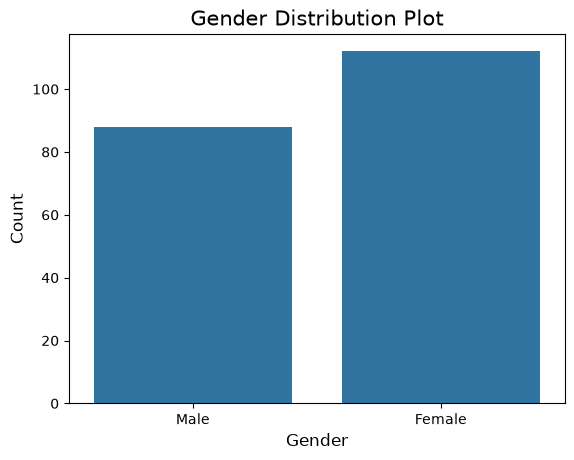

In [10]:
import matplotlib.pyplot as plt

# display a count plot for gender
sns.countplot(x='gender', data=df)
plt.title('Gender Distribution Plot', fontsize=15)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

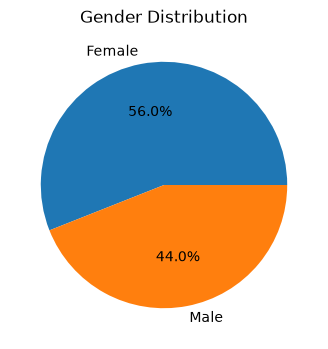

In [11]:
# if we only have few distinct values we can opt to use a Pie Chart

# Count the occurrences of each unique value
value_counts = df['gender'].value_counts()

# Create a pie chart
plt.figure(figsize=(4,4))
plt.pie(value_counts.values, labels=value_counts.index, autopct='%1.1f%%')
plt.title('Gender Distribution')
plt.show()


## Pairplot

Numerical variables are plotted against each other.

On the diagonal we get a histogram of each variable (because the variable is compared against itself)

Off the diagonal we get scatter plots of every pair

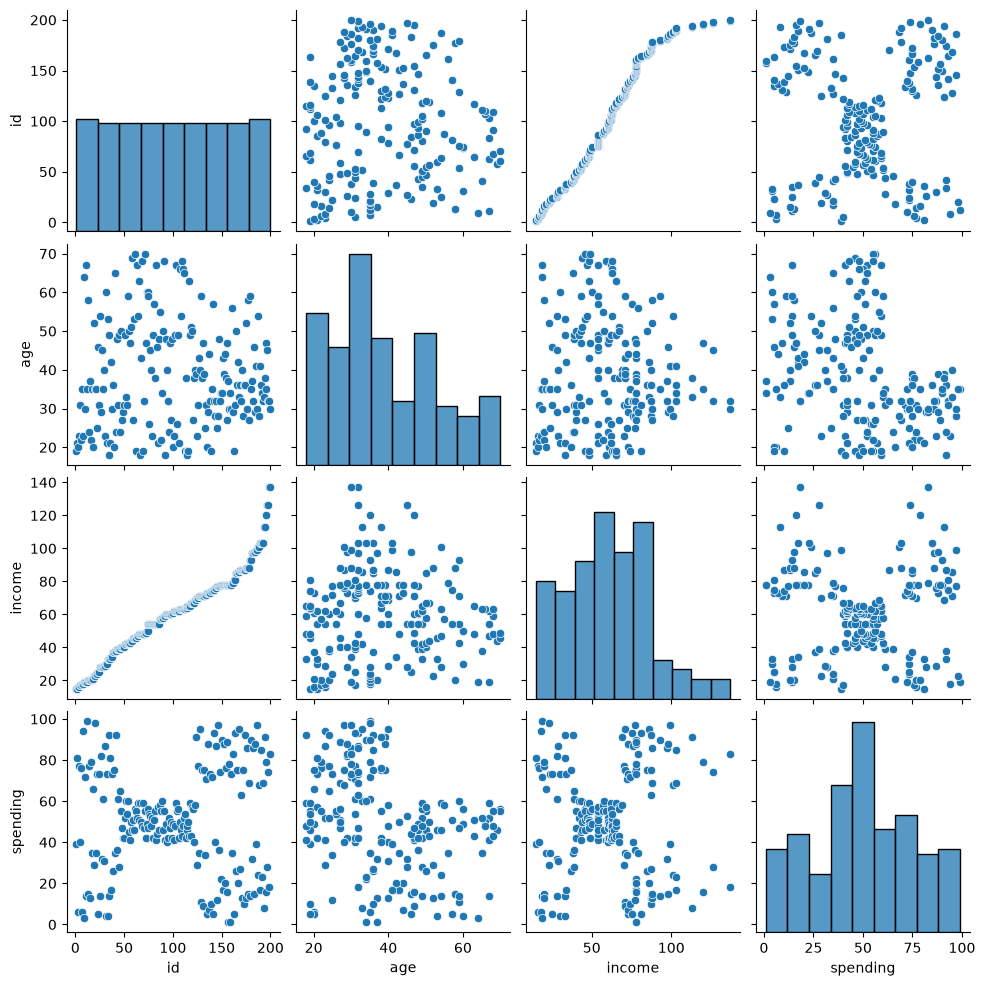

In [13]:
sns.pairplot(df)
plt.show()

Observations
- Which panel looks suspicious? Why?
    - id vs income is almost a perfect straing light. A customer id should be random.
- Which panels look like random clouds with no pattern?
    - age vs income looks like random clouds.
- Do you notice any panel with interesting groups?
    - income vs spending shows several distinct blobs.
- Is the pairplot easy ro read? What's the downside?
    - it can become bloated if we have more features
    - half of it is the same representation

### Investigating ID vs Income

Why does the scatterplot show a straight line, when these 2 should not be related?

In [14]:
df.corr(numeric_only=True)

,id,age,income,spending
id,1.000000,-0.026763,0.977548,0.013835
age,-0.026763,1.000000,-0.012398,-0.327227
income,0.977548,-0.012398,1.000000,0.009903
spending,0.013835,-0.327227,0.009903,1.000000


In [17]:
# let's look at every 20th person
df[['id', 'income']].iloc[::20]

,id,income
0,1,15
20,21,24
40,41,38
60,61,46
80,81,54
100,101,62
120,121,67
140,141,75
160,161,79
180,181,97


- What is the correlation between id and income?
    - 0.98 this means that is an almost perfect relationship.
- Look at every 20th customer. Why does this happen?
    - The table shows that when the id increases the income increases as well. Probably the dataset was sorted by income, and then an ID was attached. In reality the ID is meaningless. 
- If we fed ID to a machine learning model, what could go wrong?
    - A model could 'learn' that when an Id increases the income has to increase as well.
- What should we do with the id column?
    - Drop it 

In [18]:
customers = df.drop(columns='id')
customers.head()

,gender,age,income,spending
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


## Evaluating Age

We will look at the same variable in 3 different ways. Each chart answers a different question:

|Chart|Question it answers|
|---|---|
|Histogram (+KDE curve)|What is the overall **shape**? Where are the most values?|
|Count Plot|**Exactly** how many customers have each value?|
|Box plot|Where are the **quartiles**? Are there **outliers**?|



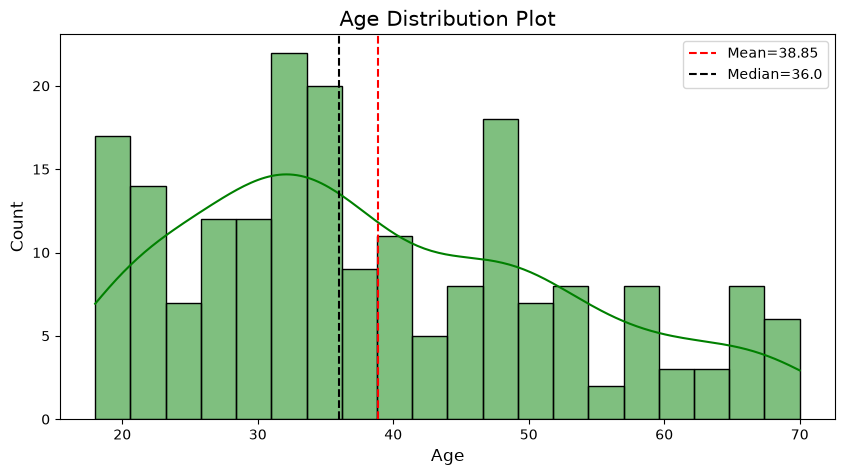

In [31]:
# distribution plot for 'age', with the mean and median marked
plt.figure(figsize=(10,5))
sns.histplot(customers['age'], color='green', bins=20, kde=True)
plt.axvline(customers['age'].mean(), color='red', linestyle='--', label=f"Mean={customers['age'].mean()}")
plt.axvline(customers['age'].median(), color='black', linestyle='--', label=f"Median={customers['age'].median()}")
plt.title('Age Distribution Plot', fontsize=15)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend()
plt.show()

C:\Users\AlanGatt\AppData\Local\Temp\ipykernel_12896\361333877.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


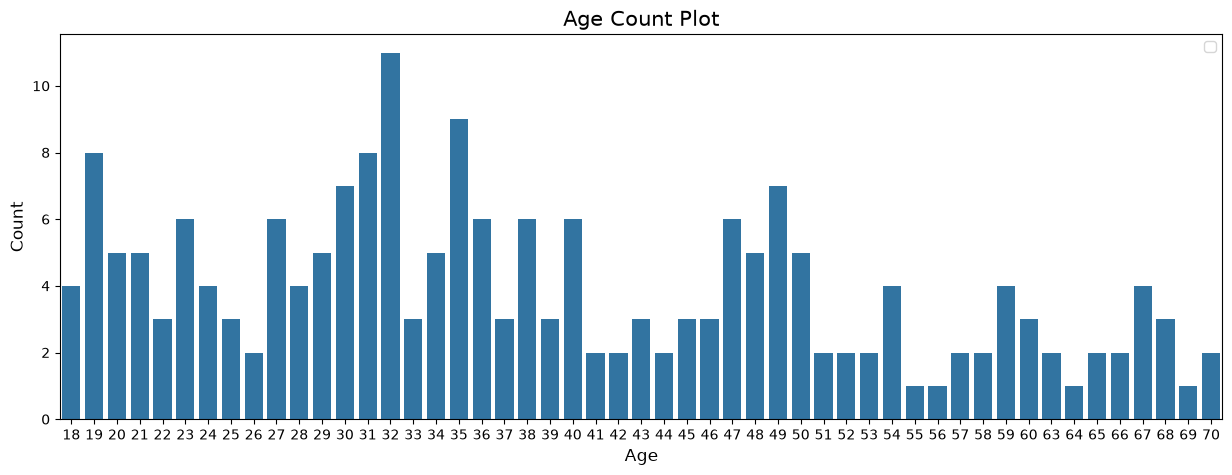

In [34]:
# count plot for 'age'
plt.figure(figsize=(15,5))
sns.countplot(x=customers['age'])
plt.title('Age Count Plot', fontsize=15)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend()
plt.show()

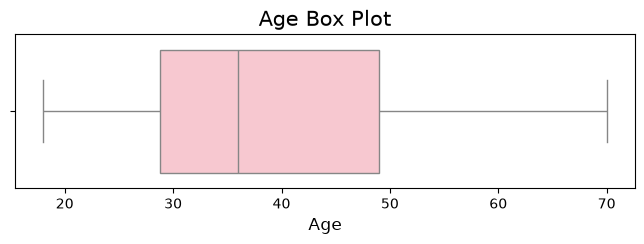

In [45]:
# box plot for age
plt.figure(figsize=(8,2))
sns.boxplot(x=customers['age'], color='pink')
plt.title('Age Box Plot', fontsize=15)
plt.xlabel('Age', fontsize=12)
plt.show()

- Where is the peak of the distribution? Which age groups are rare?
    - Most of our customers are about 25 to 50, but the busiest are 30 to 35. Over 60 customers are rare.
- Is there any skew to the data?
    - The mean (38.9) sits to the right of the median (36). So we have a slight right skew
- From the box plot, roughly what are Q1, median, Q3, outliers?
    - Q1-29, Median- 36, Q3-49, whiskers are 18 and 70; no outliers can be seen.

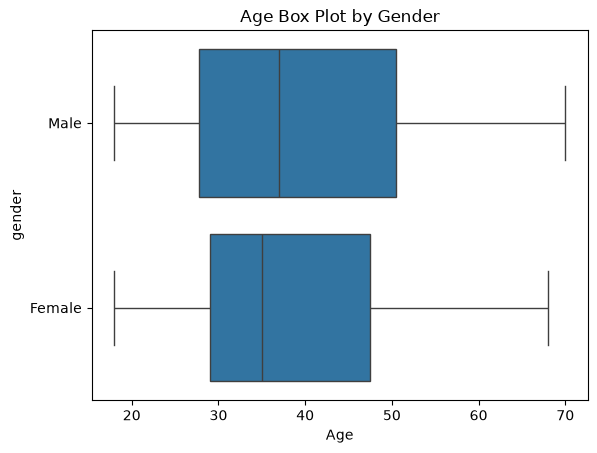

In [47]:
# Is there a variation in age distribution across gender?
sns.boxplot(x='age', y='gender', data=customers)
plt.title('Age Box Plot by Gender')
plt.xlabel('Age')
plt.show()


In [48]:
# translate the boxplot into numbers
customers.groupby('gender')['age'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,112.0,38.1,12.6,18.0,29.0,35.0,47.5,68.0
Male,88.0,39.8,15.5,18.0,27.8,37.0,50.5,70.0


## Evaluating Income

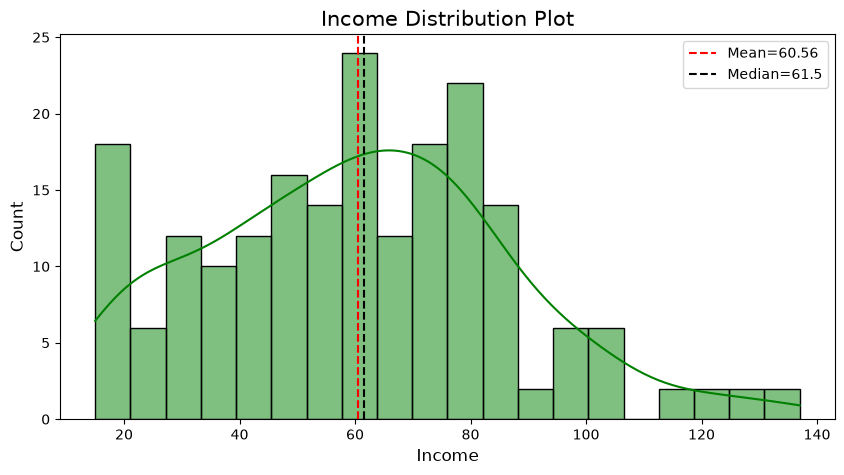

In [49]:
# distribution plot for 'income', with the mean and median marked
plt.figure(figsize=(10,5))
sns.histplot(customers['income'], color='green', bins=20, kde=True)
plt.axvline(customers['income'].mean(), color='red', linestyle='--', label=f"Mean={customers['income'].mean()}")
plt.axvline(customers['income'].median(), color='black', linestyle='--', label=f"Median={customers['income'].median()}")
plt.title('Income Distribution Plot', fontsize=15)
plt.xlabel('Income', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend()
plt.show()

C:\Users\AlanGatt\AppData\Local\Temp\ipykernel_12896\3002830538.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


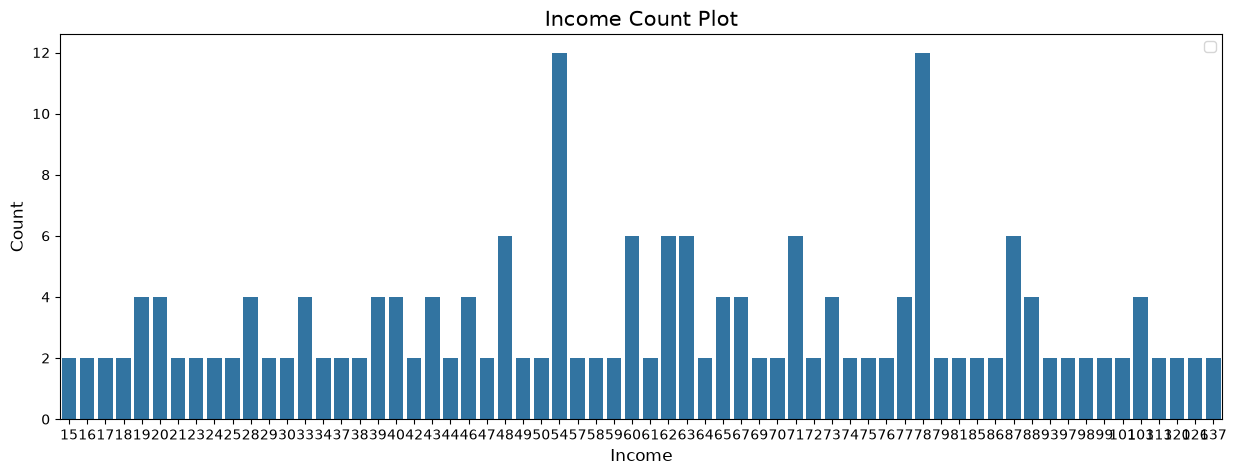

In [51]:
# count plot for 'income'
plt.figure(figsize=(15,5))
sns.countplot(x=customers['income'])
plt.title('Income Count Plot', fontsize=15)
plt.xlabel('Income', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend()
plt.show()

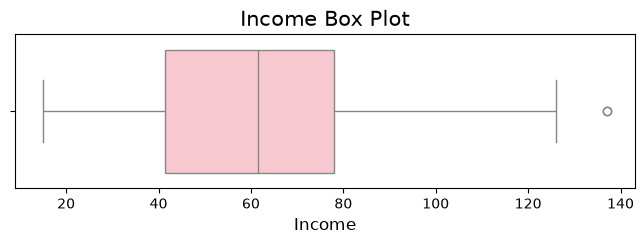

In [53]:
# box plot for income
plt.figure(figsize=(8,2))
sns.boxplot(x=customers['income'], color='pink')
plt.title('Income Box Plot', fontsize=15)
plt.xlabel('Income', fontsize=12)
plt.show()

- What is the shape of income distribution? Where do most incomes lie?
    - Most of our customers earn 40k to 80k
    - Distribution is fairly symmetric
- Do the mean and median agree?
    - Mean and median are almost the same, hence the symmetric distribution
- What do you see on the right side of the box plot?
    - This is an outlier and it's a person with around 137k income

### Finding the outlier


In [65]:
q1 = customers['income'].quantile(0.25)
q3 = customers['income'].quantile(0.75)

# Inner Quartile Range difference from q3 to q1
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

print (f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print (f"Lower Fence = {lower_fence}, Upper Fence = {upper_fence}")


customers[(customers['income'] < lower_fence) | (customers['income'] > upper_fence)]

Q1 = 41.5, Q3 = 78.0, IQR = 36.5
Lower Fence = -13.25, Upper Fence = 132.75


,gender,age,income,spending
198,Male,32,137,18
199,Male,30,137,83


There are two customers earning 137k. The box plot dew only one dot because both have the same value, so the dots stand on each other.



## Correlation

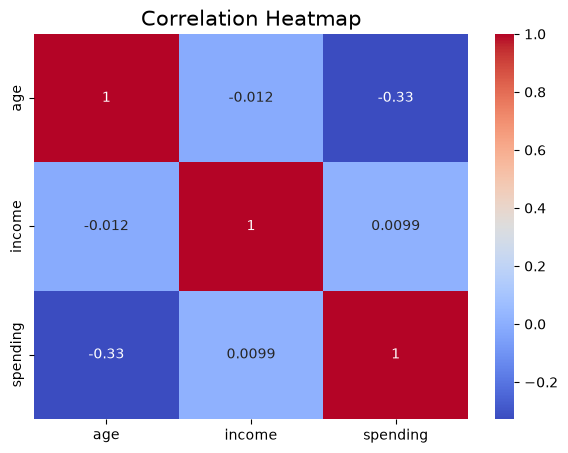

In [69]:
plt.figure(figsize=(7,5))
sns.heatmap(customers.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap', fontsize=15)
plt.show()